# Real-world DICOM analysis in Python

From the FDP session *Multimodal AI Models for Medical Imaging Analysis*. Everything here uses **real, public, de-identified DICOM files** and runs on a normal (free) Colab machine: no GPU needed, about two minutes.

1. **From the archive:** download a whole CT study and four radiologists' outlines from The Cancer Imaging Archive, sort the slices, convert to Hounsfield units, window them, view three planes and measure the nodule in 3D.
2. **Six kinds of scanner:** CT, X-ray, MRI, mammogram, ultrasound video and PET, with the tags that matter for each.
3. **Analyses and insights:** tissue composition, nodule measurements, PET tumour SUV, and a metadata audit.

**Run it:** *Runtime → Run all*, or press Shift+Enter cell by cell.

**Data:** LIDC-IDRI, UPENN-GBM, CMMD, B-mode-and-CEUS-Liver and FDG-PET-CT-Lesions from TCIA (CC BY). **Privacy:** these files were de-identified by their publishers. Never upload real patient files to Colab or any online service.

In [1]:
# Setup: get the sample pack and install the DICOM libraries (about a minute)
import glob, io, os, subprocess, sys, zipfile
if os.path.exists('../public/dicom'):                 # running inside the project folder
    PACK = '../public/dicom'
else:                                                 # Colab, or anywhere else: fetch the project
    if not os.path.exists('multimodal-medical-imaging'):
        subprocess.run(['git', 'clone', '--depth', '1', 'https://github.com/drneelmani/multimodal-medical-imaging.git'], check=True)
    PACK = 'multimodal-medical-imaging/public/dicom'
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'pydicom', 'SimpleITK'], check=True)
import numpy as np
import pydicom
import requests
import SimpleITK as sitk
import matplotlib.pyplot as plt
print(len(glob.glob(f'{PACK}/*.dcm')), 'DICOM files in the sample pack')

Cloning into 'multimodal-medical-imaging'...


12 DICOM files in the sample pack


## 1. From the archive: a whole CT study

Real analyses start from an archive. Here we download one patient's chest CT (133 files) and the four radiologists' nodule outlines (DICOM SEG) from The Cancer Imaging Archive's public API.

In [2]:
# 1. Download the CT series and the four outlines of patient LIDC-IDRI-0001 (about 70 MB)
API = 'https://services.cancerimagingarchive.net/nbia-api/services/v1'
DATA = 'data/raw'
LIDC = os.path.join(DATA, 'lidc')
series = requests.get(f'{API}/getSeries', params={'Collection': 'LIDC-IDRI', 'PatientID': 'LIDC-IDRI-0001'}, timeout=60).json()
for s in series:
    if s['Modality'] in ('CT', 'SEG'):
        d = os.path.join(LIDC, f"{s['Modality']}-{s['SeriesInstanceUID']}")
        if not os.path.isdir(d):
            z = requests.get(f'{API}/getImage', params={'SeriesInstanceUID': s['SeriesInstanceUID']}, timeout=600).content
            zipfile.ZipFile(io.BytesIO(z)).extractall(d)
        print(s['Modality'], len(glob.glob(os.path.join(d, '*.dcm'))), 'file(s)', s.get('SeriesDescription', ''))

CT 133 file(s) 


SEG 1 file(s) Segmentation of Nodule 1 - Annotation Nodule 001


SEG 1 file(s) Segmentation of Nodule 1 - Annotation IL057_127364


SEG 1 file(s) Segmentation of Nodule 1 - Annotation MI014_12127


SEG 1 file(s) Segmentation of Nodule 1 - Annotation 0


In [3]:
# A1. Read every file's header (not the pixels yet) and look at its position
ct_dir = glob.glob(os.path.join(LIDC, 'CT-*'))[0]
files = sorted(glob.glob(os.path.join(ct_dir, '*.dcm')))
headers = [pydicom.dcmread(f, stop_before_pixels=True) for f in files]

for f, h in list(zip(files, headers))[:4]:
    print(os.path.basename(f), '| instance', h.InstanceNumber,
          '| z =', float(h.ImagePositionPatient[2]), 'mm')

# Sort by height in the body (z), not by file name
order = np.argsort([float(h.ImagePositionPatient[2]) for h in headers])
headers = [headers[i] for i in order]
files = [files[i] for i in order]
print(len(files), 'slices, from z =', float(headers[0].ImagePositionPatient[2]),
      'to', float(headers[-1].ImagePositionPatient[2]), 'mm')

00000001.dcm | instance 80 | z = -207.5 mm
00000002.dcm | instance 52 | z = -137.5 mm
00000003.dcm | instance 42 | z = -112.5 mm
00000004.dcm | instance 59 | z = -155.0 mm
133 slices, from z = -340.0 to -10.0 mm


In [4]:
# A1b. A few tags that matter for analysis (and one group that matters for privacy)
h = headers[0]
for kw in ['Modality', 'Manufacturer', 'SliceThickness', 'PixelSpacing',
           'RescaleSlope', 'RescaleIntercept', 'PatientName', 'PatientIdentityRemoved']:
    print(f'{kw:24s}', h.get(kw, '(not present)'))

Modality                 CT
Manufacturer             GE MEDICAL SYSTEMS
SliceThickness           2.500000
PixelSpacing             [0.703125, 0.703125]
RescaleSlope             1
RescaleIntercept         -1024
PatientName              
PatientIdentityRemoved   YES


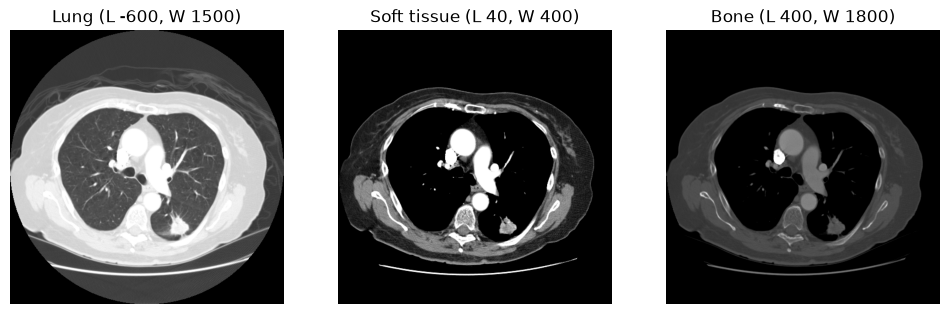

HU range on this slice: -2048 to 3071


In [5]:
# A2. Build the volume in Hounsfield units, then show one slice with three windows
volume = np.stack([pydicom.dcmread(f).pixel_array for f in files]).astype(np.float32)
volume = volume * float(h.RescaleSlope) + float(h.RescaleIntercept)   # stored → HU

def window(img, level, width):
    lo = level - width / 2
    return np.clip((img - lo) / width, 0, 1)

k = 89                                         # the slice through the nodule
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, (name, L, W) in zip(axes, [('Lung', -600, 1500), ('Soft tissue', 40, 400), ('Bone', 400, 1800)]):
    ax.imshow(window(volume[k], L, W), cmap='gray'); ax.set_title(f'{name} (L {L}, W {W})'); ax.axis('off')
plt.show()
print('HU range on this slice:', int(volume[k].min()), 'to', int(volume[k].max()))

Size (512, 512, 133) | spacing (mm) (0.7, 0.7, 2.5)


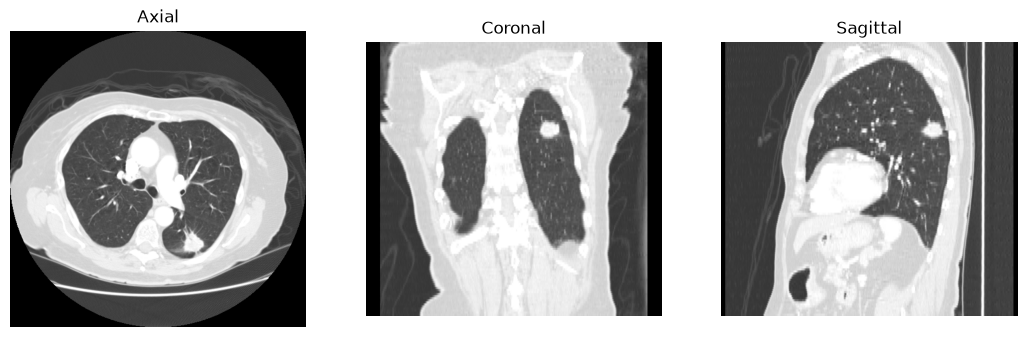

In [6]:
# A3. Let SimpleITK read and sort the series, then cut it three ways
reader = sitk.ImageSeriesReader()
reader.SetFileNames(reader.GetGDCMSeriesFileNames(ct_dir))
ct = reader.Execute()                          # already in HU, with spacing and position
arr = sitk.GetArrayFromImage(ct)               # (z, y, x)
sx, sy, sz = ct.GetSpacing()
print('Size', ct.GetSize(), '| spacing (mm)', tuple(round(s, 2) for s in ct.GetSpacing()))

z, y, x = 89, 367, 316                         # the nodule
fig, axes = plt.subplots(1, 3, figsize=(13, 4.5))
axes[0].imshow(window(arr[z], -600, 1500), cmap='gray'); axes[0].set_title('Axial')
axes[1].imshow(window(arr[::-1, y, :], -600, 1500), cmap='gray', aspect=sz / sx); axes[1].set_title('Coronal')
axes[2].imshow(window(arr[::-1, :, x], -600, 1500), cmap='gray', aspect=sz / sy); axes[2].set_title('Sagittal')
for ax in axes: ax.axis('off')
plt.show()

In [7]:
# 1e. Measure the nodule in 3D from the four radiologists' DICOM SEG files, on the CT grid
z0, dz = ct.GetOrigin()[2], ct.GetSpacing()[2]
readers = []
for f in sorted(glob.glob(os.path.join(LIDC, 'SEG-*', '*.dcm'))):
    s = pydicom.dcmread(f)
    m = np.zeros(arr.shape, bool)
    for frame, item in zip(s.pixel_array.reshape(-1, s.Rows, s.Columns), s.PerFrameFunctionalGroupsSequence):
        m[int(round((float(item.PlanePositionSequence[0].ImagePositionPatient[2]) - z0) / dz))] |= frame > 0
    readers.append(m)
dice = lambda a, b: 2 * (a & b).sum() / (a.sum() + b.sum())
for i, m in enumerate(readers, 1):
    print(f'Reader {i}: {m.sum() * sx * sy * sz / 1000:.1f} ml, mean {arr[m].mean():.0f} HU, on {np.unique(np.nonzero(m)[0]).size} slices')
pairs = [dice(readers[i], readers[j]) for i in range(4) for j in range(i + 1, 4)]
print(f'Insight: the four radiologists agree with Dice {min(pairs):.2f}-{max(pairs):.2f}; judge any model against that spread')

Reader 1: 7.3 ml, mean -132 HU, on 8 slices


Reader 2: 5.7 ml, mean -12 HU, on 7 slices
Reader 3: 6.1 ml, mean -47 HU, on 8 slices
Reader 4: 6.8 ml, mean -88 HU, on 9 slices


Insight: the four radiologists agree with Dice 0.84-0.90; judge any model against that spread


## 2. Six kinds of scanner

Small *teaching copies* of real DICOM files: every original tag kept, private tags removed, pixels downsampled where needed, and each change written into the file's `DerivationDescription`.

In [8]:
# D1. Open every file and print the tags that matter for each kind of scan
pack = sorted(glob.glob(f'{PACK}/*.dcm'))
for f in pack:
    d = pydicom.dcmread(f)
    frames = int(d.get('NumberOfFrames', 1))
    print(f"{os.path.basename(f):28s} {d.Modality:3s} {d.Rows}x{d.Columns}"
          f"{f' x{frames} frames' if frames > 1 else ''}  {d.PhotometricInterpretation:11s} {d.BitsStored}-bit"
          f"  units: {'HU' if d.Modality == 'CT' else d.get('Units', '-')}")
print()
print('Change recorded in one file:', pydicom.dcmread(pack[0]).DerivationDescription)

ct-fdg-lung.dcm              CT  512x512  MONOCHROME2 12-bit  units: HU
ct-lidc-0001.dcm             CT  512x512  MONOCHROME2 16-bit  units: HU
mammo-cmmd-d2-0333.dcm       MG  573x478  MONOCHROME2 8-bit  units: -
mri-flair-upenn-00001.dcm    MR  256x192  MONOCHROME2 16-bit  units: -
pet-fdg-lung.dcm             PT  400x400  MONOCHROME2 16-bit  units: BQML
seg-fdg-lung-slice.dcm       SEG 400x400  MONOCHROME2 1-bit  units: -
seg-lidc-0001-reader1.dcm    SEG 512x512 x8 frames  MONOCHROME2 1-bit  units: -
seg-lidc-0001-reader2.dcm    SEG 512x512 x7 frames  MONOCHROME2 1-bit  units: -
seg-lidc-0001-reader3.dcm    SEG 512x512 x8 frames  MONOCHROME2 1-bit  units: -
seg-lidc-0001-reader4.dcm    SEG 512x512 x9 frames  MONOCHROME2 1-bit  units: -
us-liver-ceus.dcm            US  162x292 x21 frames  RGB         8-bit  units: -
xray-lidc-0001.dcm           DX  505x505  MONOCHROME2 14-bit  units: -

Change recorded in one file: Teaching copy for an FDP slide deck: private tags removed; pixels unc

Mammogram: ImageLaterality = R | ViewPosition = not recorded
Ultrasound: (21, 162, 292, 3) | FrameTime 537.3984 ms | duration 11.3 s


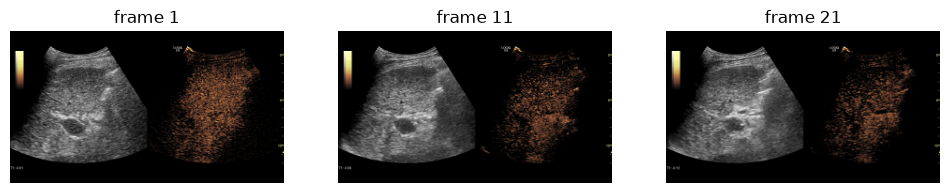

In [9]:
# D2. Modality-specific details: which breast (mammogram), and an ultrasound file is a video
mg = pydicom.dcmread(f'{PACK}/mammo-cmmd-d2-0333.dcm')
print('Mammogram: ImageLaterality =', mg.ImageLaterality, '| ViewPosition =', mg.get('ViewPosition', 'not recorded'))
us = pydicom.dcmread(f'{PACK}/us-liver-ceus.dcm')
cine = us.pixel_array                                   # (frames, rows, columns, 3): colour video
print('Ultrasound:', cine.shape, '| FrameTime', float(us.FrameTime), 'ms | duration', round(cine.shape[0] * float(us.FrameTime) / 1000, 1), 's')
fig, axes = plt.subplots(1, 3, figsize=(12, 3))
for ax, k in zip(axes, [0, cine.shape[0] // 2, cine.shape[0] - 1]):
    ax.imshow(cine[k]); ax.set_title(f'frame {k + 1}'); ax.axis('off')
plt.show()

In [10]:
# D3. PET pixels are Bq/ml; the file's own tags turn them into SUV (body weight, decay-corrected)
pet = pydicom.dcmread(f'{PACK}/pet-fdg-lung.dcm')
r = pet.RadiopharmaceuticalInformationSequence[0]
tm = lambda t: int(t[:2]) * 3600 + int(t[2:4]) * 60 + float(t[4:])
minutes = (tm(pet.SeriesTime) - tm(r.RadiopharmaceuticalStartTime)) / 60
dose_now = float(r.RadionuclideTotalDose) * 2 ** (-minutes * 60 / float(r.RadionuclideHalfLife))
suv = pet.pixel_array * float(pet.RescaleSlope) * float(pet.PatientWeight) * 1000 / dose_now
print(f'{r.Radiopharmaceutical}: {float(r.RadionuclideTotalDose) / 1e6:.0f} MBq, scan {minutes:.1f} min later'
      f' -> {dose_now / 1e6:.1f} MBq left; weight {pet.PatientWeight} kg; max SUV on this slice {suv.max():.1f}')

Fluorodeoxyglucose: 300 MBq, scan 60.1 min later -> 205.3 MBq left; weight 61 kg; max SUV on this slice 14.2


Same frame of reference: True | CT 512 px at 0.802734375 mm; PET 400 px at 2.03642 mm


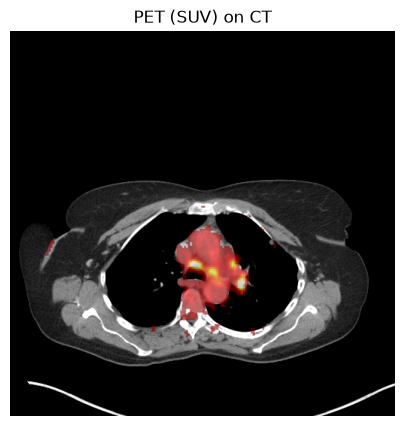

In [11]:
# D4. PET/CT fusion: the PET and CT files share a frame of reference, so their positions line up
ct2 = pydicom.dcmread(f'{PACK}/ct-fdg-lung.dcm')
hu2 = ct2.pixel_array * float(ct2.RescaleSlope) + float(ct2.RescaleIntercept)
print('Same frame of reference:', pet.FrameOfReferenceUID == ct2.FrameOfReferenceUID,
      '| CT', ct2.Rows, 'px at', float(ct2.PixelSpacing[0]), 'mm; PET', pet.Rows, 'px at', float(pet.PixelSpacing[0]), 'mm')
# Place both in millimetres and draw PET on top of CT
ext = lambda d: [float(d.ImagePositionPatient[0]), float(d.ImagePositionPatient[0]) + d.Columns * float(d.PixelSpacing[1]),
                 float(d.ImagePositionPatient[1]) + d.Rows * float(d.PixelSpacing[0]), float(d.ImagePositionPatient[1])]
plt.figure(figsize=(5, 5))
plt.imshow(window(hu2, 40, 400), cmap='gray', extent=ext(ct2))
plt.imshow(np.ma.masked_less(suv, 1.5), cmap='hot', vmin=0, vmax=8, alpha=0.6, extent=ext(pet))
plt.xlim(ext(ct2)[:2]); plt.ylim(ext(ct2)[2:]); plt.axis('off'); plt.title('PET (SUV) on CT'); plt.show()

## 3. Analyses and insights

Four short analyses, each ending in one insight. The same code exists as `notebook/dicom_insights.py` in the project, for running from a terminal.

In [12]:
# E0. Helpers shared by E1-E4 (also the top of dicom_insights.py)
import os
import numpy as np
import pydicom
import matplotlib.pyplot as plt

FIG_DIR = None                       # set to a folder to save figures instead of showing them


def load(name):
    return pydicom.dcmread(os.path.join(PACK, name))


def values(ds):
    """Pixel values in the file's real units (rescale slope and intercept applied)."""
    return ds.pixel_array * float(ds.get('RescaleSlope', 1)) + float(ds.get('RescaleIntercept', 0))


def seg_on(seg, img):
    """A DICOM SEG mask placed on one image slice, using both files' positions and orientations."""
    sh = seg.SharedFunctionalGroupsSequence[0]
    sy, sx = (float(v) for v in sh.PixelMeasuresSequence[0].PixelSpacing)
    half = float(sh.PixelMeasuresSequence[0].SliceThickness) / 2
    iop = np.array(sh.PlaneOrientationSequence[0].ImageOrientationPatient, float)
    o, ipp, (py, px) = np.array(img.ImageOrientationPatient, float), np.array(img.ImagePositionPatient, float), (float(v) for v in img.PixelSpacing)
    frames = seg.pixel_array.reshape(-1, seg.Rows, seg.Columns)
    for frame, item in zip(frames, seg.PerFrameFunctionalGroupsSequence):
        pos = np.array(item.PlanePositionSequence[0].ImagePositionPatient, float)
        if abs(pos[2] - ipp[2]) < half:
            r, c = np.mgrid[0:img.Rows, 0:img.Columns]
            p = ipp + c[..., None] * o[:3] * px + r[..., None] * o[3:] * py - pos
            sc, sr = np.rint(p @ iop[:3] / sx).astype(int), np.rint(p @ iop[3:] / sy).astype(int)
            ok = (sr >= 0) & (sr < seg.Rows) & (sc >= 0) & (sc < seg.Columns)
            mask = np.zeros((img.Rows, img.Columns), bool)
            mask[ok] = frame[sr[ok], sc[ok]] > 0
            return mask
    return np.zeros((img.Rows, img.Columns), bool)


def longest(mask, ds):
    """Longest distance (mm) between two pixels of a 2D mask."""
    ys, xs = np.nonzero(mask)
    pts = np.stack([xs * float(ds.PixelSpacing[1]), ys * float(ds.PixelSpacing[0])], 1)
    return float(np.sqrt(((pts[:, None] - pts[None]) ** 2).sum(-1)).max())


def suv_factor(pet):
    """Body-weight SUV per Bq/ml, decay-corrected to series start, from the PET file's tags."""
    r = pet.RadiopharmaceuticalInformationSequence[0]
    tm = lambda t: int(t[:2]) * 3600 + int(t[2:4]) * 60 + float(t[4:])
    dose = float(r.RadionuclideTotalDose) * 2 ** (-(tm(pet.SeriesTime) - tm(r.RadiopharmaceuticalStartTime)) / float(r.RadionuclideHalfLife))
    return float(pet.PatientWeight) * 1000 / dose


def show(fig, name):
    if FIG_DIR:
        os.makedirs(FIG_DIR, exist_ok=True)
        fig.savefig(os.path.join(FIG_DIR, f'{name}.png'), dpi=120, bbox_inches='tight')
        plt.close(fig)
        print('figure saved:', os.path.join(FIG_DIR, f'{name}.png'))
    else:
        plt.show()

lung           332 cm²
fat            205 cm²
soft tissue    126 cm²
bone            38 cm²
Insight: lung is 47% of the tissue on this slice


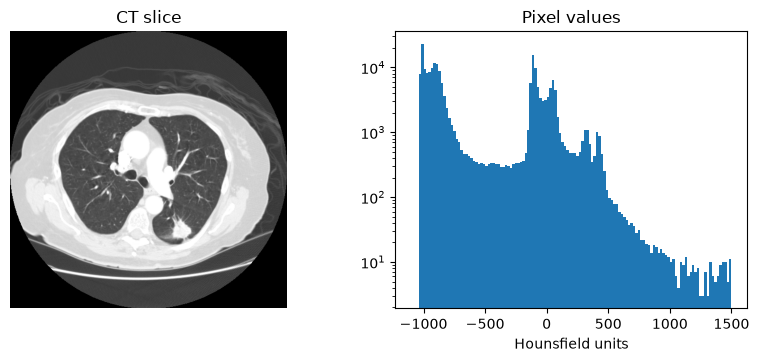

In [13]:
# E1. CT: what tissue is on this slice? Hounsfield units sort the pixels; pixel size gives cm²
ct = load('ct-lidc-0001.dcm')
hu = values(ct)
cm2 = float(ct.PixelSpacing[0]) * float(ct.PixelSpacing[1]) / 100
bands = {'lung': (-950, -500), 'fat': (-150, -30), 'soft tissue': (-30, 100), 'bone': (300, 3000)}
area = {k: ((hu >= lo) & (hu < hi)).sum() * cm2 for k, (lo, hi) in bands.items()}
for k, v in area.items():
    print(f'{k:12s} {v:5.0f} cm²')
print(f"Insight: lung is {100 * area['lung'] / sum(area.values()):.0f}% of the tissue on this slice")
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].imshow(np.clip((hu + 1350) / 1500, 0, 1), cmap='gray'); ax[0].set_title('CT slice'); ax[0].axis('off')
ax[1].hist(hu.ravel(), bins=130, range=(-1100, 1500), log=True); ax[1].set_xlabel('Hounsfield units'); ax[1].set_title('Pixel values')
show(fig, 'E1_tissue')

Reader 1: 7.3 cm³, longest 31 mm, mean 5 HU
Reader 2: 5.7 cm³, longest 32 mm, mean 31 HU
Reader 3: 6.1 cm³, longest 30 mm, mean 27 HU
Reader 4: 6.8 cm³, longest 32 mm, mean 28 HU
Insight: same nodule, same images, volumes differ by 28%


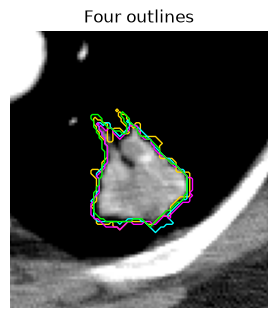

In [14]:
# E2. CT: measure the nodule each of four radiologists outlined (DICOM SEG files)
ct = load('ct-lidc-0001.dcm')
hu = values(ct)
fig, ax = plt.subplots(figsize=(3.6, 3.6))
ax.imshow(np.clip((hu + 160) / 400, 0, 1), cmap='gray')
volumes = []
for r, colour in zip(range(1, 5), ['gold', 'cyan', 'magenta', 'lime']):
    seg = load(f'seg-lidc-0001-reader{r}.dcm')
    pm = seg.SharedFunctionalGroupsSequence[0].PixelMeasuresSequence[0]
    volumes.append((seg.pixel_array > 0).sum() * float(pm.PixelSpacing[0]) * float(pm.PixelSpacing[1]) * float(pm.SliceThickness) / 1000)
    m = seg_on(seg, ct)
    print(f'Reader {r}: {volumes[-1]:.1f} cm³, longest {longest(m, ct):.0f} mm, mean {hu[m].mean():.0f} HU')
    ax.contour(m, levels=[0.5], colors=colour, linewidths=1)
ys, xs = np.nonzero(m)
ax.set_xlim(xs.min() - 30, xs.max() + 30); ax.set_ylim(ys.max() + 30, ys.min() - 30); ax.axis('off'); ax.set_title('Four outlines')
print(f'Insight: same nodule, same images, volumes differ by {100 * (max(volumes) / min(volumes) - 1):.0f}%')
show(fig, 'E2_nodule')

SUVmax 14.2 | SUVmean 3.4 | area 18.8 cm²
Insight: tumour-to-background ratio 4.3: about 4x more sugar


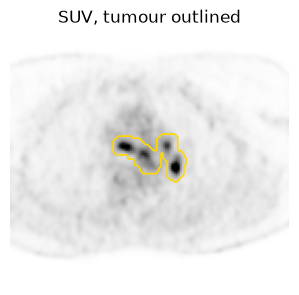

In [15]:
# E3. PET: how hot is the tumour? SUV from the file's own tags; tumour from the expert's DICOM SEG
pet = load('pet-fdg-lung.dcm')
suv = values(pet) * suv_factor(pet)
lesion = seg_on(load('seg-fdg-lung-slice.dcm'), pet)
background = (suv > 0.3) & ~lesion
area = lesion.sum() * float(pet.PixelSpacing[0]) * float(pet.PixelSpacing[1]) / 100
print(f'SUVmax {suv[lesion].max():.1f} | SUVmean {suv[lesion].mean():.1f} | area {area:.1f} cm²')
print(f'Insight: tumour-to-background ratio {suv[lesion].mean() / suv[background].mean():.1f}: about {suv[lesion].mean() / suv[background].mean():.0f}x more sugar')
fig, ax = plt.subplots(figsize=(3.6, 3.6))
ax.imshow(suv, cmap='gray_r', vmin=0, vmax=8); ax.contour(lesion, levels=[0.5], colors='gold', linewidths=1.2)
ys, xs = np.nonzero(lesion)
ax.set_xlim(xs.min() - 50, xs.max() + 50); ax.set_ylim(ys.max() + 50, ys.min() - 50); ax.axis('off'); ax.set_title('SUV, tumour outlined')
show(fig, 'E3_pet')

In [16]:
# E4. Audit the metadata of every image file in the pack
print(f"{'File':28s}{'Modality':9s}{'Identity removed':17s}{'Birth date':11s}{'Pixel size':14s}Private tags")
missing = 0
files = sorted(f for f in os.listdir(PACK) if f.endswith('.dcm') and not f.startswith('seg-'))
for f in files:
    d = load(f)
    size = d.get('PixelSpacing') or d.get('ImagerPixelSpacing')
    missing += size is None
    private = sum(e.tag.is_private for e in d)
    print(f"{f:28s}{d.Modality:9s}{d.get('PatientIdentityRemoved', 'not stated'):17s}{d.get('PatientBirthDate') or 'empty':11s}"
          f"{(f'{float(size[0]):.3f} mm' if size else 'not recorded'):14s}{private}")
print(f'Insight: {missing} of {len(files)} files record no pixel size, so nothing in them can be measured in mm')

File                        Modality Identity removed Birth date Pixel size    Private tags
ct-fdg-lung.dcm             CT       YES              empty      0.803 mm      0
ct-lidc-0001.dcm            CT       YES              empty      0.703 mm      0
mammo-cmmd-d2-0333.dcm      MG       YES              empty      0.376 mm      0
mri-flair-upenn-00001.dcm   MR       YES              empty      0.938 mm      0
pet-fdg-lung.dcm            PT       YES              empty      2.036 mm      0
us-liver-ceus.dcm           US       YES              empty      not recorded  0
xray-lidc-0001.dcm          DX       YES              empty      not recorded  0
Insight: 2 of 7 files record no pixel size, so nothing in them can be measured in mm


## What to take away

* **Units and geometry live in the tags.** Hounsfield units, pixel size, slice position, PET dose and timing: without them, the pixels cannot be measured.
* **Experts disagree.** Four radiologists' volumes for one nodule differ by more than a quarter.
* **Check before you trust.** Some files record no pixel size; an audit finds that in seconds.
* These are research analyses on public data, not clinical measurements.